In [13]:
import numpy as np
import matplotlib.pyplot as plt
import time

# фотонов на МэВ
YIELD = 10000 

In [14]:
class PMT:
    def __init__(self, pos, r):
        self.pos = pos
        self.r = r
    
    def n_photoelectrons(self, a):
        # Пуассон умеет работать с массивами
        return np.random.poisson(a)


class Detector:
    def __init__(self, R, N, r, a):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.pmts = []
        self._make_pmts()
        
        # кэшируем позиции в массив (N, 3) для быстрого поиска
        self._pmt_positions = np.array([p.pos for p in self.pmts])
    
    def _make_pmts(self):
        i = np.arange(self.N) + 0.5
        phi = np.arccos(1 - 2*i/self.N)
        theta = np.pi * (1 + 5**0.5) * i
        x = self.R * np.sin(phi) * np.cos(theta)
        y = self.R * np.sin(phi) * np.sin(theta)
        z = self.R * np.cos(phi)
        
        for k in range(self.N):
            self.pmts.append(PMT(np.array([x[k], y[k], z[k]]), self.r))
    
    def hit_point(self, origin, directions):
        # origin: (3,), directions: (3, N)
        # Возвращает точки пересечения (3, N)
        a = np.sum(directions**2, axis=0) # (N,)
        b = 2 * np.dot(origin, directions) # (N,)
        c = np.dot(origin, origin) - self.R**2 # скаляр
        
        disc = b**2 - 4*a*c
        
        # маска, где дискриминант положительный
        mask = disc >= 0
        t = np.full(directions.shape[1], np.nan)
        t[mask] = (-b[mask] + np.sqrt(disc[mask])) / (2*a[mask])
        
        # отсекаем отрицательные t
        t[t < 0] = np.nan
        
        # точки пересечения
        hits = origin[:, np.newaxis] + t * directions
        return hits
    
    def find_pmt(self, points):
        # points: (3, N)
        N = points.shape[1]
        indices = np.full(N, -1, dtype=int)
        
        # маска валидных точек (не nan)
        mask = ~np.isnan(points[0])
        
        if np.sum(mask) == 0:
            return indices
        
        valid_pts = points[:, mask] # (3, N_v)
        
        # расстояния от точек до всех ФЭУ
        # valid_pts.T: (N_v, 3), _pmt_positions: (N_pmt, 3)
        dists = np.linalg.norm(valid_pts.T[:, np.newaxis, :] - self._pmt_positions[np.newaxis, :, :], axis=2)
        
        nearest = np.argmin(dists, axis=1)
        min_d = np.min(dists, axis=1)
        
        # проверяем, попали ли в радиус
        hit_mask = min_d <= self.r
        
        indices[mask] = np.where(hit_mask, nearest, -1)
        return indices

In [15]:
class Source:
    def __init__(self, Y=YIELD, L_att=8.0):
        self.Y = Y
        self.L_att = L_att
    
    def n_photons(self, E):
        return np.random.poisson(self.Y * E)
    
    def directions(self, N):
        phi = np.random.uniform(0, 2*np.pi, N)
        cos_t = np.random.uniform(-1, 1, N)
        sin_t = np.sqrt(1 - cos_t**2)
        x = sin_t * np.cos(phi)
        y = sin_t * np.sin(phi)
        z = cos_t
        return np.array([x, y, z])
    
    def photon_array(self, E):
        N = self.n_photons(E)
        if N == 0:
            return np.zeros((3, 0))
        return self.directions(N)

In [16]:
def simulate_event_vec(det, src, E, source_pos=None, attenuation=True):
    if source_pos is None:
        source_pos = np.zeros(3)
    
    dirs = src.photon_array(E)
    if dirs.shape[1] == 0:
        return 0
    
    hits = det.hit_point(source_pos, dirs)
    pmt_idx = det.find_pmt(hits)
    
    # оставляем только попавшие в ФЭУ
    mask = pmt_idx != -1
    pmt_idx = pmt_idx[mask]
    hits = hits[:, mask]
    
    if len(pmt_idx) == 0:
        return 0
        
    if attenuation:
        dists = np.linalg.norm(hits - source_pos[:, None], axis=0)
        p = np.exp(-dists / src.L_att)
        # разыгрываем, кто выжил
        survive = np.random.uniform(0, 1, len(p)) < p
        pmt_idx = pmt_idx[survive]
        
    if len(pmt_idx) == 0:
        return 0
        
    # генерим фотоэлектроны для всех выживших разом
    pe = np.random.poisson(det.a, size=len(pmt_idx))
    return np.sum(pe)

In [17]:
def simulate_event_batch(det, src, E, source_pos=None, att=True):
    if source_pos is None:
        source_pos = np.zeros(3)
    
    dirs = src.photon_array(E)
    total_pe = 0
    
    # честный перебор по одному фотону
    for i in range(dirs.shape[1]):
        d = dirs[:, i]
        
        # считаем пересечение со сферой
        a = np.dot(d, d)
        b = 2 * np.dot(source_pos, d)
        c = np.dot(source_pos, source_pos) - det.R**2
        disc = b**2 - 4*a*c
        
        if disc < 0:
            continue
        t = (-b + np.sqrt(disc)) / (2*a)
        if t < 0:
            continue
            
        hit = source_pos + t * d
        
        # ищем ближайший ФЭУ обычным циклом
        idx = -1
        for j, p in enumerate(det.pmts):
            if np.linalg.norm(hit - p.pos) <= p.r:
                idx = j
                break
        
        if idx == -1:
            continue
            
        # затухание
        if att:
            dist = np.linalg.norm(hit - source_pos)
            if np.random.uniform(0, 1) > np.exp(-dist / src.L_att):
                continue
                
        total_pe += np.random.poisson(det.a)
        
    return total_pe

In [18]:
det = Detector(R=2.0, N=40, r=0.1, a=0.5)
src = Source()
E_test = 1.0
N_events = 100

# старый способ (с циклом внутри)
start = time.perf_counter()
q_loop = [simulate_event_batch(det, src, E_test) for _ in range(N_events)]
t_loop = time.perf_counter() - start

# новый способ
start = time.perf_counter()
q_vec = [simulate_event_vec(det, src, E_test) for _ in range(N_events)]
t_vec = time.perf_counter() - start

print(f"Циклы: {t_loop:.2f} сек")
print(f"Numpy: {t_vec:.2f} сек")
print(f"Ускорение: {t_loop / t_vec:.1f}x")
print()
print(f"Средний заряд (циклы): {np.mean(q_loop):.1f}")
print(f"Средний заряд (numpy): {np.mean(q_vec):.1f}")

Циклы: 192.80 сек
Numpy: 3.05 сек
Ускорение: 63.2x

Средний заряд (циклы): 97.8
Средний заряд (numpy): 97.8


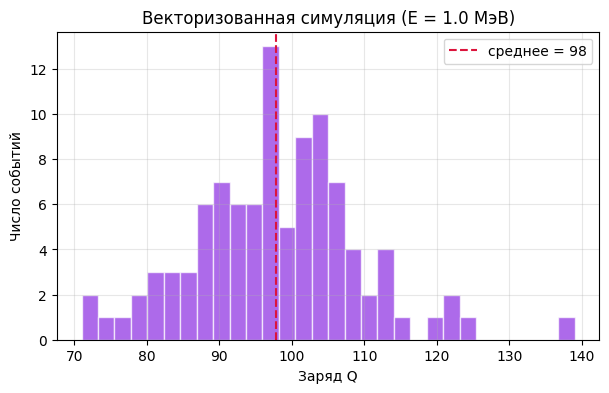

In [19]:
plt.figure(figsize=(7, 4))
plt.hist(q_vec, bins=30, alpha=0.7, color='blueviolet', edgecolor='white')
plt.axvline(np.mean(q_vec), color='crimson', linestyle='--', label=f'среднее = {np.mean(q_vec):.0f}')
plt.xlabel('Заряд Q')
plt.ylabel('Число событий')
plt.title(f'Векторизованная симуляция (E = {E_test} МэВ)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()